# **Petunjuk TTS**

Silakan simpan file ke dalam bentuk **TTS_NLP_NIM.ipynb**. Soal terbagi teori dan praktek; untuk teori langsung tuliskan jawaban dalam bentuk TEXT, sedangkan untuk praktek, tuliskan koding untuk dapat menampilkan hasil seperti yang diminta. Jangan gunakan AI, saya pasti tahu 😏

Setelah selesai mengerjakan, silakan unggah ke GClass. Waktu kalian 90 menit. Jangan sampai terlambat ya...tidak ada toleransi untuk keterlambatan.

Have fun!

**SOAL TEORI**

1. Berikan penjelasan singkat, apa itu Pemrosesan Bahasa Alami atau NLP? (Tidak lebih dari 50 kata).
2. Ada kurang lebih 5 tantangan dari Pemrosesan Bahasa Alami. Sebutkan dan jelaskan, tidak lebih dari 200 kata.
3. Jelaskan secara singkat arti dari gambar berikut: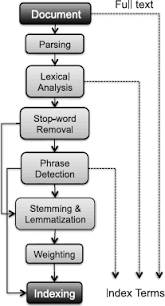

**Jawaban Soal Teori**



1. Nlp adalah bidang yang mengajari/melatih komputer agar bisa memahami, merespon, dan mengolah bahasa manusia.
2. - Productivity: Bahasa yang terus berekembang jadi banyak yang belum terdaftar di kamus masa lalu/baku.
   - Ambiguous: Satu kata/kalimat sering memiliki makna ganda jadi komputer kesulitan menemukan arti yang pas.
   - Variability: Gaya berbahasa sangat bervariasi jadi komputer sering gagal memahami bentuk kalimat yang berbeda tapi memiliki arti yang sama
   - Diversity: Banyaknya bahasa di dunia yang membuat satu aturan kode tidak bisa dipakai kepada semua bahasa.
   - Sparsity: Pilihan kata manusia sangat luas mengakibatkan komputer seringkali tidak lengkap dalam mencakupnya.
3. Bagan Text Pre-processing tersebut menggambarkan alur untuk mengubah dokumen teks mentah yang berantakan (Full text) menjadi kumpulan kata bersih yang siap dijadikan indeks (Index Terms) . Prosesnya berjalan runtut ke bawah, dimulai dari memecah komponen dokumen (Parsing) , memotong teks menjadi kata tunggal (Lexical Analysis/Tokenisasi) , membuang kata sambung tidak penting (Stop-word Removal) , mendeteksi gabungan kata khusus (Phrase Detection), mengembalikan kata berimbuhan ke kata dasarnya (Stemming/Lemmatization) , hingga memberikan nilai bobot numerik pada kata tersebut (Weighting) sebelum akhirnya diindeks (Indexing).

**SOAL PRAKTEK**

1. BBC News

In [1]:
# install pandas profiling
!pip install https://github.com/pandas-profiling/pandas-profiling/archive/master.zip

  Using cached https://github.com/pandas-profiling/pandas-profiling/archive/master.zip
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [9]:
# import libraries sesuai kebutuhan kita
import pandas as pd
from ydata_profiling import ProfileReport

In [8]:
# Ambil data dari https://gitlab.com/gguibon/ensae-ml4nlp-storage/-/raw/master/bbc-news-data.zip
!wget https://gitlab.com/gguibon/ensae-ml4nlp-storage/-/raw/master/bbc-news-data.zip
!unzip bbc-news-data.zip

--2026-06-10 03:56:23--  https://gitlab.com/gguibon/ensae-ml4nlp-storage/-/raw/master/bbc-news-data.zip
Resolving gitlab.com (gitlab.com)... 172.65.251.78, 2606:4700:90:0:f22e:fbec:5bed:a9b9
Connecting to gitlab.com (gitlab.com)|172.65.251.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1896286 (1.8M) [application/octet-stream]
Saving to: ‘bbc-news-data.zip’

bbc-news-data.zip   100%[===================>]   1.81M  --.-KB/s    in 0.02s   

2026-06-10 03:56:23 (107 MB/s) - ‘bbc-news-data.zip’ saved [1896286/1896286]

Archive:  bbc-news-data.zip
  inflating: bbc-news-data.csv       


In [10]:
# load data tersebut ke DataFrame kita
df = pd.read_csv('bbc-news-data.csv', sep='\t')
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


In [12]:
# tampilkan jenis berita yang ada dalam kolom Kategori
df['category'].unique().tolist()

['business', 'entertainment', 'politics', 'sport', 'tech']

In [13]:
# Buat dashboard otomatis dari dataset kita dengan menggunakan Profile Report (pandas profiling)
profile = ProfileReport(df, title="BBC News Data Profiling Report")
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 4/4 [00:01<00:00,  2.36it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

2. Ambil data dari Twitter dengan keyword: "**Arsenal**", maksimal 250 data. Setelah itu tampilkan dalam dataframe. Ambil hanya kolom **full_text** untuk dianalisa. Lakukan ***cleaning*** (tidak boleh ada simbol), ***case_folding*** (huruf diubah menjadi kecil semua), ***tokenisasi*** (dipecah menjadi token), ***filtering*** dan ***stemming*** (diubah menjadi kata dasar), untuk kolom **full_text**.

In [45]:
!pip install nltk Sastrawi

import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [46]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [63]:
nama_file = 'arsenal.csv'
df_raw = pd.read_csv(nama_file)
print(f"Berhasil memuat {len(df_raw)} baris data!")

col_name = 'full_text' if 'full_text' in df_raw.columns else 'text'

df_text = df_raw[[col_name]].copy()

Berhasil memuat 204 baris data!


In [64]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
display(df_raw['text'])

,text
0,"Arsenal belum pernah menjuarai Liga Champions, tetapi lihatlah berapa banyak fans rival yang merayakan kegagalan mereka kemarin. \n\nBukan karena Arsenal sedang mempertahankan gelar, melainkan semata-mata karena mereka tidak ingin melihat Arsenal berhasil.\n\nItu juga menjadi"
1,"Mereka bilang PSG akan menghancurkan Arsenal seperti yang mereka lakukan terhadap Bayern.\n\nNamun kenyataannya, mereka tidak hanya gagal mengalahkan Arsenal dalam 120 menit, mereka juga tidak mampu mencetak satu pun gol dari open play tapi adu penalti menjadi faktor penentu. https://t.co/xyEbJjOCho"
2,Gas pol volume speaker Anda:\n\nIni adalah salah satu video paling indah yang pernah gue tonton. Editingnya keren.\n\nTidak ada penggemar Arsenal yang tidak akan merasa tersentuh atau termotivasi oleh video ini. \n\nBahkan para haters pun hampir bisa meneteskan air mata.\n\nPELAJARANNYA:
3,COYG 🏆\n#ArsenalWomen #AWFC #COYG #Arsenal #Goonergirl https://t.co/5C8dYSuBD5
4,"7 nya kayak jalan di tempat Min…\n\nKapan mau nambah lagi? Eh mesti lolos ke UCL dulu ya… baru bisa nambah.\n\nCoba lagi musim depan, jangan menyerah 👊"
5,"Yang nyalahin Big Gabi, kalian coba ingat2 sepanjang musim ini berapa kali dia nyelamatin Arsenal, dengan itu mungkin bisa sedekit nenangin emosi kalian. Di match tadi pun, kalau bukan karena dia juga Arsenal bisa hancur sebelum extra time. Arsenal bisa juara PL setelah 22 tahun https://t.co/I6HL9MILcq"
6,💚 sangat amat bersyukur arsenal kalah.\nbtw sebagai fans chelsea sy sangat respect sama fans liverpool 👍🏽🙏🏾\n\nkalo kalian sukanya fans dari klub mana?? https://t.co/LbcY6Wx3Q3
7,Hakimi scores.\n\nPSG - ✅✅❌✅\nArsenal - ✅❌✅
8,"Arsenal musim ini emang luar biasa.\n\n22 tahun puasa liga, akhirnya mereka akhiri juga. Tapi Eropa adalah hutan yang berbeda. \n\nDi Eropa, Arsenal belum pernah sekalipun nyentuh trofi paling bergengsi ini. Bukan tahun ini, bukan di era Wenger, bukan di era manapun sepanjang sejarah https://t.co/TYOjStscus"
9,Zubimendi x Merino x Raya 🇪🇸❤️ https://t.co/Dnck45X836


In [66]:
stop_words = set(stopwords.words('indonesian'))
stop_words.update(['yg', 'di', 'ke', 'rt', 'nya', 'ya', 'sih', 'dong', 'kalo', 'aja', 'ini', 'itu'])

factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [67]:
def clean_and_lower(text):
    text = str(text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

df_text['cleaned'] = df_text[col_name].apply(clean_and_lower)

In [68]:
df_text['tokenized'] = df_text['cleaned'].apply(word_tokenize)

In [69]:
df_text['filtered'] = df_text['tokenized'].apply(lambda tokens: [w for w in tokens if w not in stop_words])

In [70]:
df_text['stemmed'] = df_text['filtered'].apply(lambda tokens: [stemmer.stem(w) for w in tokens])

In [71]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
display(df_text)

,text,cleaned,tokenized,filtered,stemmed
0,"Arsenal belum pernah menjuarai Liga Champions, tetapi lihatlah berapa banyak fans rival yang merayakan kegagalan mereka kemarin. \n\nBukan karena Arsenal sedang mempertahankan gelar, melainkan semata-mata karena mereka tidak ingin melihat Arsenal berhasil.\n\nItu juga menjadi",arsenal belum pernah menjuarai liga champions tetapi lihatlah berapa banyak fans rival yang merayakan kegagalan mereka kemarin bukan karena arsenal sedang mempertahankan gelar melainkan semata mata karena mereka tidak ingin melihat arsenal berhasil itu juga menjadi,"[arsenal, belum, pernah, menjuarai, liga, champions, tetapi, lihatlah, berapa, banyak, fans, rival, yang, merayakan, kegagalan, mereka, kemarin, bukan, karena, arsenal, sedang, mempertahankan, gelar, melainkan, semata, mata, karena, mereka, tidak, ingin, melihat, arsenal, berhasil, itu, juga, menjadi]","[arsenal, menjuarai, liga, champions, lihatlah, fans, rival, merayakan, kegagalan, kemarin, arsenal, mempertahankan, gelar, mata, arsenal, berhasil]","[arsenal, juara, liga, champions, lihat, fans, rival, raya, gagal, kemarin, arsenal, tahan, gelar, mata, arsenal, hasil]"
1,"Mereka bilang PSG akan menghancurkan Arsenal seperti yang mereka lakukan terhadap Bayern.\n\nNamun kenyataannya, mereka tidak hanya gagal mengalahkan Arsenal dalam 120 menit, mereka juga tidak mampu mencetak satu pun gol dari open play tapi adu penalti menjadi faktor penentu. https://t.co/xyEbJjOCho",mereka bilang psg akan menghancurkan arsenal seperti yang mereka lakukan terhadap bayern namun kenyataannya mereka tidak hanya gagal mengalahkan arsenal dalam menit mereka juga tidak mampu mencetak satu pun gol dari open play tapi adu penalti menjadi faktor penentu,"[mereka, bilang, psg, akan, menghancurkan, arsenal, seperti, yang, mereka, lakukan, terhadap, bayern, namun, kenyataannya, mereka, tidak, hanya, gagal, mengalahkan, arsenal, dalam, menit, mereka, juga, tidak, mampu, mencetak, satu, pun, gol, dari, open, play, tapi, adu, penalti, menjadi, faktor, penentu]","[bilang, psg, menghancurkan, arsenal, lakukan, bayern, kenyataannya, gagal, mengalahkan, arsenal, menit, mencetak, gol, open, play, adu, penalti, faktor, penentu]","[bilang, psg, hancur, arsenal, laku, bayern, nyata, gagal, kalah, arsenal, menit, cetak, gol, open, play, adu, penalti, faktor, tentu]"
2,Gas pol volume speaker Anda:\n\nIni adalah salah satu video paling indah yang pernah gue tonton. Editingnya keren.\n\nTidak ada penggemar Arsenal yang tidak akan merasa tersentuh atau termotivasi oleh video ini. \n\nBahkan para haters pun hampir bisa meneteskan air mata.\n\nPELAJARANNYA:,gas pol volume speaker anda ini adalah salah satu video paling indah yang pernah gue tonton editingnya keren tidak ada penggemar arsenal yang tidak akan merasa tersentuh atau termotivasi oleh video ini bahkan para haters pun hampir bisa meneteskan air mata pelajarannya,"[gas, pol, volume, speaker, anda, ini, adalah, salah, satu, video, paling, indah, yang, pernah, gue, tonton, editingnya, keren, tidak, ada, penggemar, arsenal, yang, tidak, akan, merasa, tersentuh, atau, termotivasi, oleh, video, ini, bahkan, para, haters, pun, hampir, bisa, meneteskan, air, mata, pelajarannya]","[gas, pol, volume, speaker, salah, video, indah, gue, tonton, editingnya, keren, penggemar, arsenal, tersentuh, termotivasi, video, haters, meneteskan, air, mata, pelajarannya]","[gas, pol, volume, speaker, salah, video, indah, gue, tonton, editingnya, keren, gemar, arsenal, sentuh, motivasi, video, haters, tetes, air, mata, ajar]"
3,COYG 🏆\n#ArsenalWomen #AWFC #COYG #Arsenal #Goonergirl https://t.co/5C8dYSuBD5,coyg,[coyg],[coyg],[coyg]
4,"7 nya kayak jalan di tempat Min…\n\nKapan mau nambah lagi? Eh mesti lolos ke UCL dulu ya… baru bisa nambah.\n\nCoba lagi musim depan, jangan menyerah 👊",nya kayak jalan di tempat min kapan mau nambah lagi eh mesti lolos ke ucl dulu ya baru bisa nambah coba lagi musim depan jangan menyerah,"[nya, kayak, jalan, di, tempat, min, kap

In [72]:
df_text.to_csv('hasil_nlp_arsenal.csv', index=False)
print("\nData berhasil diproses dan disimpan ke 'hasil_nlp_arsenal.csv'")


Data berhasil diproses dan disimpan ke 'hasil_nlp_arsenal.csv'


3. Buatlah perhitungan **Term Weighting ~ TF-IDF** untuk kumpulan dokumen sebagai berikut:

*   d1 = "aku cinta kamu"
*   d2 = "aku cinta kamu dan dia"

*   d3 = "aku cinta kamu tapi kamu cinta dia"
*   d4 = "aku memang cinta kamu tapi aku milih dia"

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs = [
    "aku cinta kamu",
    "aku cinta kamu dan dia",
    "aku cinta kamu tapi kamu cinta dia",
    "aku memang cinta kamu tapi aku milih dia"
]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(docs)
feature_names = vectorizer.get_feature_names_out()
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names, index=['d1', 'd2', 'd3', 'd4'])
df_tfidf

,aku,cinta,dan,dia,kamu,memang,milih,tapi
d1,0.577350,0.577350,0.000000,0.000000,0.577350,0.000000,0.000000,0.000000
d2,0.349893,0.349893,0.670497,0.427970,0.349893,0.000000,0.000000,0.000000
d3,0.279742,0.559483,0.000000,0.342164,0.559483,0.000000,0.000000,0.422641
d4,0.483326,0.241663,0.000000,0.295588,0.241663,0.463096,0.463096,0.365110
